# **Assignment 3: Data Visualization + Web-scraping**

## EDA of Refah Iranian Dataset

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

# Abstract

This report continues the Exploratory Data Analysis (EDA) of the **Refah Iranian** dataset. The primary objective of this project is to visualize patterns and features in the dataset.

# Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install arabic_reshaper

In [3]:
!pip install python-bidi

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from matplotlib.category import UnitData

# We need these libraries for Farsi writting
import arabic_reshaper
import bidi.algorithm

wr.filterwarnings('ignore')

# Display all columns in DataFrame format
pd.set_option('display.max_columns', None)

# **Read dataset**

This part is a repeatition of a part of the previous assingment. We load the dataset and perform some cleaning.

In [5]:
df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW2/nemone_2_darsadi_1402.csv")

In [6]:
df = df_org
df.head()

As you can see, the dataset is contains many cells that are 'NaN'. It seems that this data set is not clean, thus, a lot of work should be done!

## Data Structure
In this part, we explain the structure of the dataset by using the pandas function.
* Column names and type
* Number of unique values in each column
* Percentage of null value in each columns

First let's have a look at data type of each cell:

In [7]:
# df.info()

In [8]:
# df.describe()

## Count number of unique values in each column

In [9]:
# Count number of distinct elements
df.nunique(axis=0)

,0
id,1697816
Parent_Id,595688
GenderId,2
Age,100
ISBimarKhas,1
IsMalool,1
Malool_shedat,4
Dashboard_postalcode7Digits,196389
isurban,2
SabteAhval_provincename,31


# Data Visualization

In [10]:
# df['Age'].value_counts()

Let's plot distribuiton of a Age in the dataset. We use Histograms for this:


## ***Pie Chart***: Gender identification


We don't know the values is 'GenderId'. It has 1 and 2. so we perform another analysis to find out. we search for the people whose 'parent_id' is equal to its 'id. (people who are head of the household). We assume that in a normal population sample, most heads of the household are men. so by performing the following analysis, we find out that '1' is equal to 'Male' and '2' is the same as 'female'.

In [11]:
(df[df['Parent_Id'] == df['id']])['GenderId'].value_counts()

,count
GenderId,
1,462770
2,132918


Also let's plot a pie chart of gender distribution :

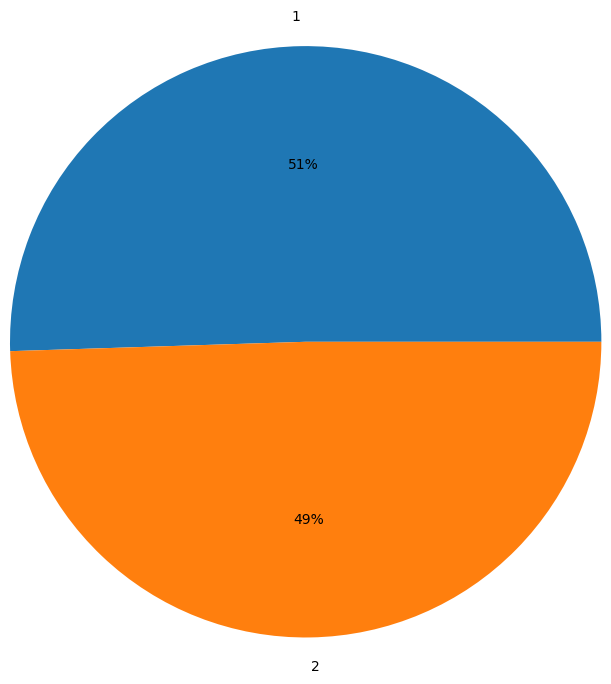

In [12]:
df['GenderId'].value_counts()[0:2].plot.pie(autopct='%1.0f%%',radius=2,ylabel='')
plt.show()

It makes since, acorrding to this [research](https://www.ined.fr/en/everything_about_population/demographic-facts-sheets/faq/more-men-or-women-in-the-world/#:~:text=The%20number%20of%20men%20and,496%20are%20women%20(49.6%25).).

Also, it seems that we don't have gender bias in our dataset.

# Handling Missing and Incorrect Data
In this part, we try to clean data and prepare for EDA and other analysis.

In [13]:
to_categorical_columns = ['Malool_shedat','SabteAhval_provincename','SabteAhval_countyname']
for column in to_categorical_columns:
  df[column] = df[column].astype('category').cat.codes

# ***Box Plot***: Car price

Now, suppose we want to draw boxplot for the car price of people who are in Decile 10 and are older than 68. (suppose we will use the logorithm of car price.)

Also, if we found any outlier, we will annotate its ID.

3030


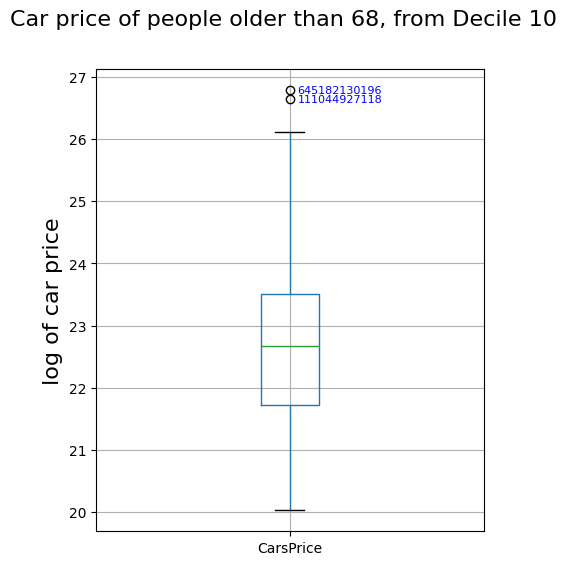

In [14]:
# Filter the results
selected_results = (df[(df['Decile'] == 10) & (df['CarsPrice'] > 0) & (df['Age'] >= 68)])
print(len(selected_results))
selected_results['CarsPrice'] = np.log(selected_results['CarsPrice'])
# Create the histogram
selected_results.boxplot(column='CarsPrice',figsize=(5,6),grid=True)

plt.suptitle('Car price of people older than 68, from Decile 10', fontsize=16)
plt.ylabel('log of car price',fontsize=16)

# Let's label the outliers
q1,q2,q3 = selected_results.CarsPrice.quantile([0.25,0.5,0.75]).values
outlier_top_lim = q3 + 1.5 * (q3 - q1)
outlier_bottom_lim = q1 - 1.5 * (q3 - q1)
for row in selected_results.itertuples():
    val = row.CarsPrice
    if val > outlier_top_lim or val < outlier_bottom_lim:
        plt.text(1.02, val, row.id, ha='left', va='center',color='blue',fontsize=8)

plt.show()

# ***Line Plot*** :

Let's plot mean of Daramad by Decile.*italicized text*

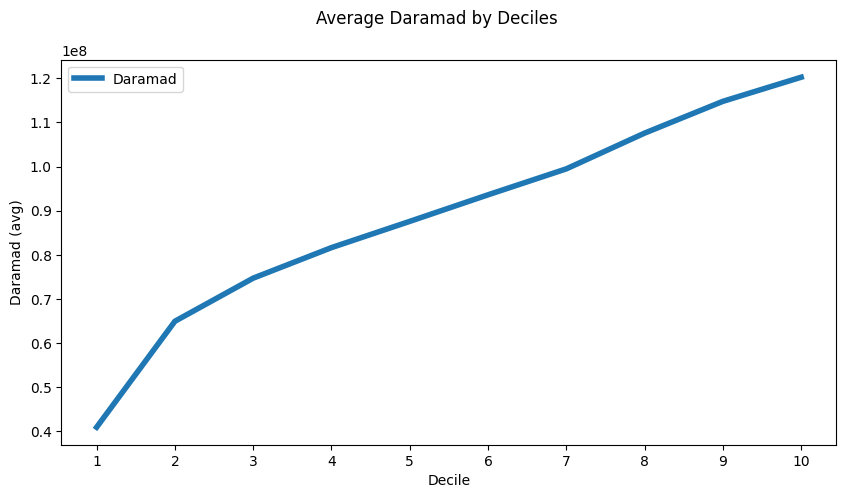

In [15]:
decile_avg_daramad = df[['Decile' , 'Daramad']].groupby('Decile').mean().reset_index()
decile_avg_daramad.plot.line(x='Decile',y='Daramad',figsize=(10,5),lw=4)

# Now let's setup the labels, titles and format y axis as percentages
plt.suptitle('Average Daramad by Deciles')
plt.ylabel('Daramad (avg)')
plt.xticks(np.arange(1,11,1))
plt.show()

# ***Line Plot with Uncertinity*** :

Now Let's do the same thing, but seperately for men and women. Also we will add out uncertinity to this.

In [16]:
# Calculate deciles for 'Daramad'
# Group by deciles and calculate the average 'Daramad' for each decile
decile_avg_daramad1 = df[df['GenderId'] == 1].groupby('Decile')['Daramad'].mean()
err1 = df[df['GenderId'] == 1].groupby('Decile')['Daramad'].std()

decile_avg_daramad2 = df[df['GenderId'] == 2].groupby('Decile')['Daramad'].mean()
err2 = df[df['GenderId'] == 2].groupby('Decile')['Daramad'].std()

# Create a new DataFrame with deciles and average 'Daramad'
decile_df1 = pd.DataFrame({'Decile': decile_avg_daramad1.index, 'Avg_Daramad': decile_avg_daramad1.values})
decile_df2 = pd.DataFrame({'Decile': decile_avg_daramad2.index, 'Avg_Daramad': decile_avg_daramad2.values})

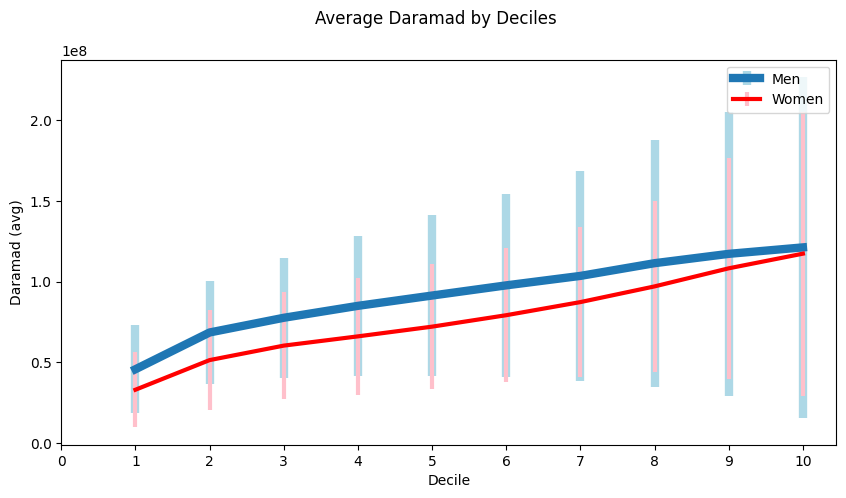

In [17]:
ax = decile_df1.plot.line(x='Decile',y='Avg_Daramad',figsize=(10,5),lw=6 , yerr = err1 , ecolor = 'LightBlue')
decile_df2.plot.line(x='Decile',y='Avg_Daramad',figsize=(10,5),lw=3 , ax=ax , color='red' , yerr=err2 , ecolor='pink')


# Now let's setup the labels, titles and format y axis as percentages
plt.suptitle('Average Daramad by Deciles')
plt.legend(['Men','Women'])
plt.ylabel('Daramad (avg)')
plt.xticks(np.arange(0,11,1))
plt.show()

# Bar plot:

histograms are a special kind of bar plot. Let's draw 'Age' distribution:

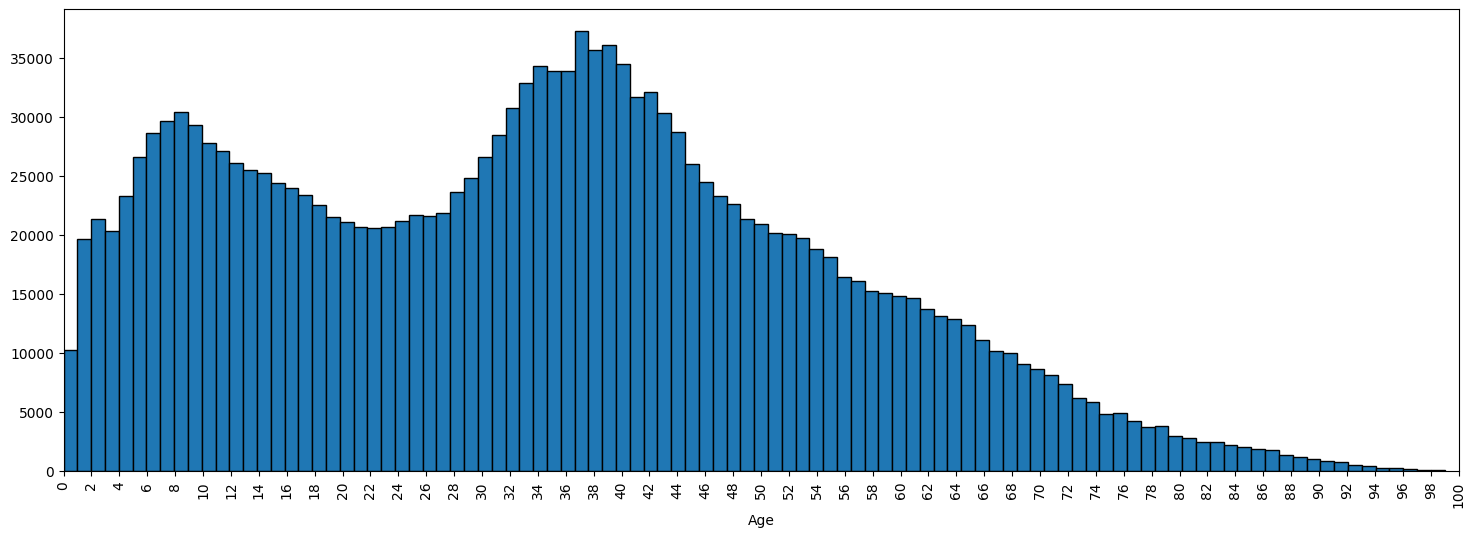

In [18]:
plt.figure(figsize=(18,6))
plt.hist(df['Age'],
         histtype="bar",
         bins=100,
         align='mid',
         edgecolor='black',
        )


plt.xlim((1,100))
plt.xlabel("Age" )
plt.xticks(np.arange(0,101,2), rotation='vertical')

plt.show()


For the sake of Stacked bar plot, let's find out how many people in each Decile, has 'MojavezSenfi'. we count seperately for men and women.

    Decile  GenderId  HasMojavezSenfi  count
0        1         1                1    500
1        1         2                1    483
2        2         1                1   1207
3        2         2                1    817
4        3         1                1   1482
5        3         2                1    701
6        4         1                1   2028
7        4         2                1    874
8        5         1                1   2521
9        5         2                1   1016
10       6         1                1   3048
11       6         2                1   1160
12       7         1                1   3922
13       7         2                1   1253
14       8         1                1   5001
15       8         2                1   1493
16       9         1                1   6683
17       9         2                1   1688
18      10         1                1  11720
19      10         2                1   2180


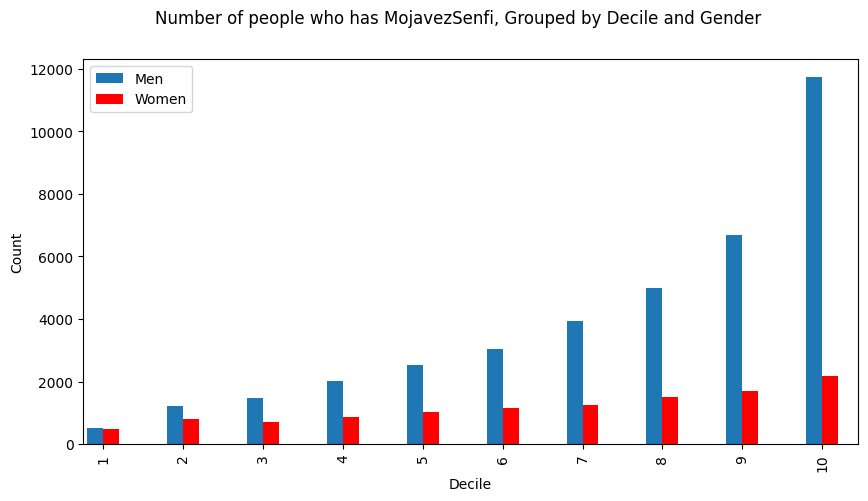

In [19]:
# Group by Decile and GenderId, then count the number of rows where 'HasMojavezSenfi' is 1.
# Remember that 'GenderId' = 1 is used for men.
mojavez_count_by_decile_gender = df[df['HasMojavezSenfi'] == 1].groupby(['Decile', 'GenderId'])['HasMojavezSenfi'].value_counts().reset_index()
print(mojavez_count_by_decile_gender)
# Create the bar plot


# Create the histogram
ax = mojavez_count_by_decile_gender[mojavez_count_by_decile_gender.GenderId == 1].plot.bar(x='Decile',y='count',position=1,width=.2,figsize=(10,5))
mojavez_count_by_decile_gender[mojavez_count_by_decile_gender.GenderId == 2].plot.bar(x='Decile',y='count',ax=ax,color='red',position=0,width=.2)

# Now let's setup the labels, titles and format y axis as percentages
plt.suptitle('Number of people who has MojavezSenfi, Grouped by Decile and Gender')
plt.legend(['Men','Women'])
plt.ylabel('Count')
plt.xlabel('Decile')
plt.show()

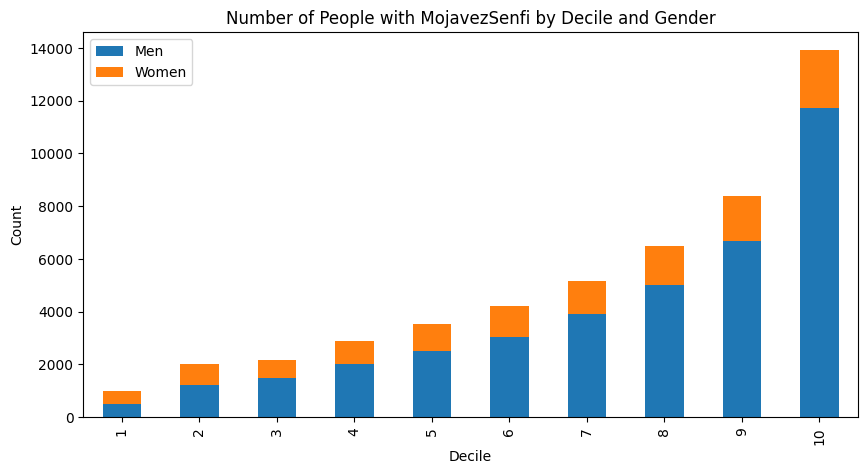

In [32]:
# Group data by Decile and GenderId, then count the number of rows where 'HasMojavezSenfi' is 1.
mojavez_count_by_decile_gender = df[df['HasMojavezSenfi'] == 1].groupby(['Decile', 'GenderId'])['HasMojavezSenfi'].count().unstack()

# Create the stacked bar plot
ax = mojavez_count_by_decile_gender.plot(kind='bar', stacked=True, figsize=(10, 5))

# Set labels, title, and legend
plt.xlabel('Decile')
plt.ylabel('Count')
plt.title('Number of People with MojavezSenfi by Decile and Gender')
plt.legend(['Men', 'Women'])

plt.show()

### Another bar plot:

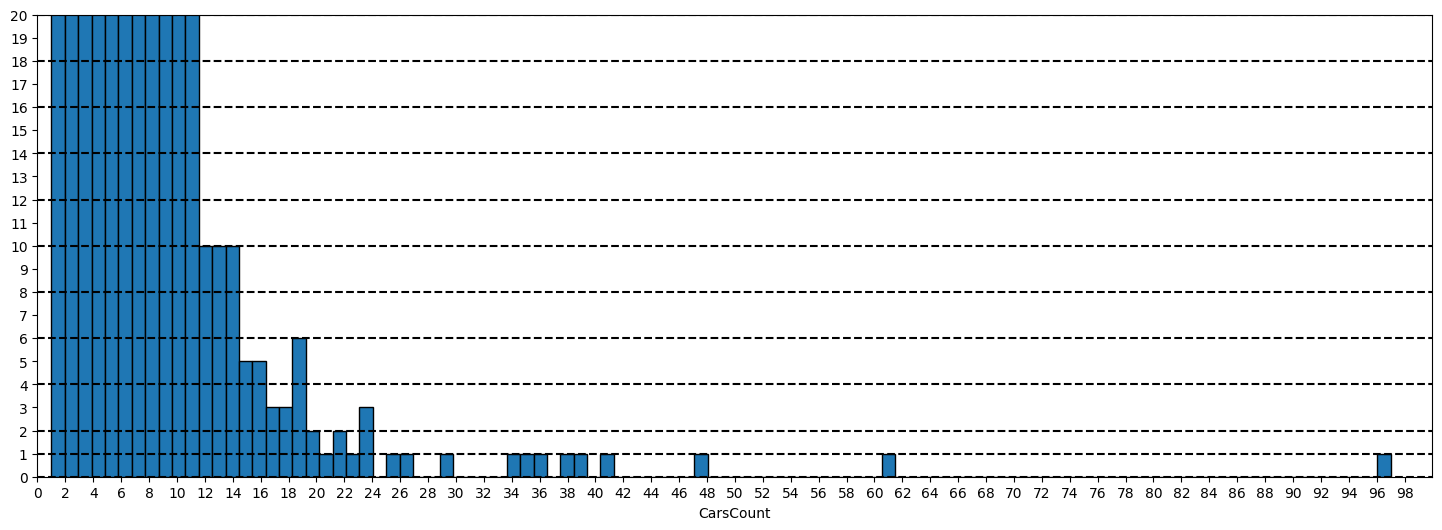

In [20]:
# Distribution of the frequency of registered vehicles by individuals.
plt.figure(figsize=(18,6))
plt.hist(df["CarsCount"],
         histtype="bar",
         bins=100,
         align='mid',
         edgecolor='black'
        )

plt.hlines(np.arange(0,30,2) ,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')
plt.hlines(1,xmin=0, xmax=100 , linestyles='dashed' ,colors='black')

plt.ylim((0,20))
plt.xlim((1,100))
plt.xlabel("CarsCount" )
plt.xticks(np.arange(0,100,2))
plt.yticks(np.arange(0,21,1))


plt.show()

# ***Scatter Plot***:

Now we will examine whether the number of vehicles is related to the individual's Decile.


Text(0.5, 0, 'CarsCount')

<Figure size 640x480 with 0 Axes>

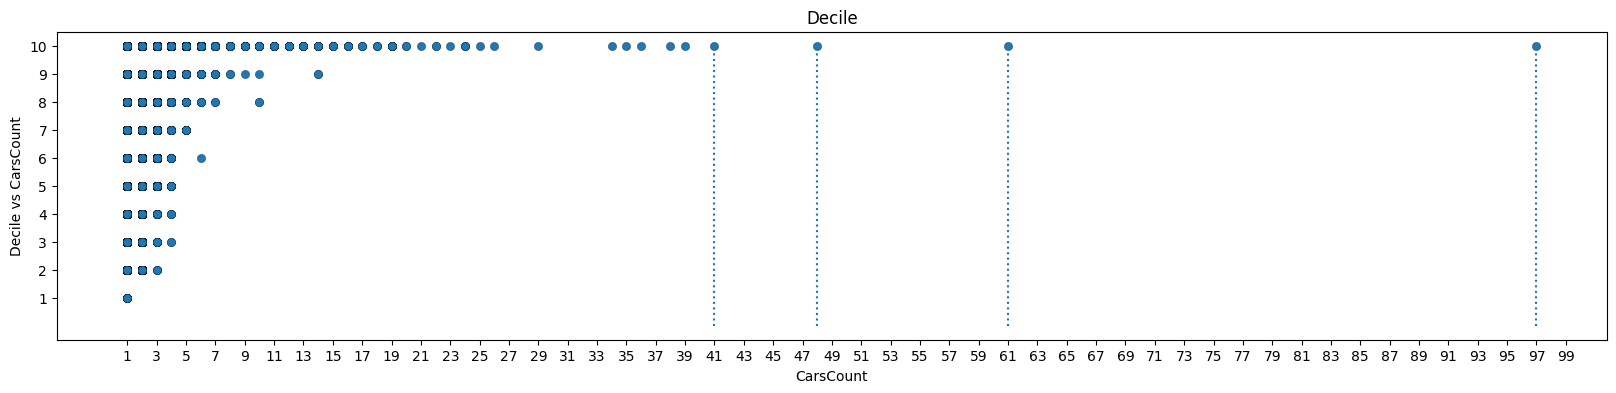

In [21]:
df['Decile']=df['Decile'].astype(int)

plt.clf()
plt.figure(figsize=(20,4))

plt.scatter(df['CarsCount'],
            df['Decile'],
            edgecolors='black',
            marker='o',
            linewidths=0.2
            )

plt.vlines([41,61,97,48],ymin=0,ymax=10 ,linestyles='dotted')

plt.xticks(np.arange(1,100,2))
plt.yticks(np.arange(1,11,1))

plt.title('Decile')
plt.ylabel('Decile vs CarsCount')
plt.xlabel('CarsCount')

Also, Let's plot people's car price vs their car count.

Text(0, 0.5, 'CarsPrice')

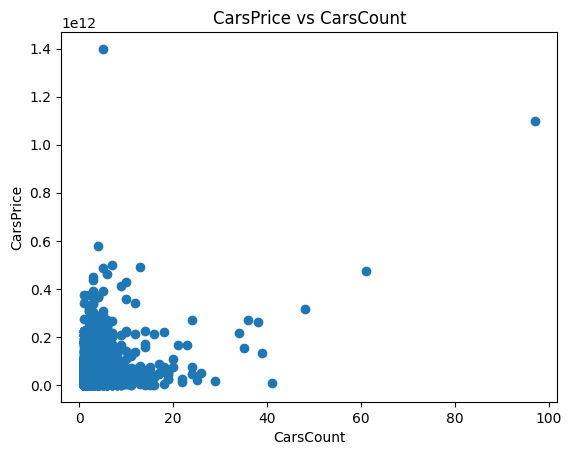

In [22]:
plt.scatter(df["CarsCount"], df["CarsPrice"] )

plt.xlabel("CarsCount")
plt.title("CarsPrice vs CarsCount")
plt.ylabel("CarsPrice")

We observe that individuals in higher percentiles have taken more air travel, while individuals in lower percentiles have taken more ground travel.



# ***Bubble Chart*** :

In [23]:
# Sample 100 rows where 'CarsPrice' and 'Daramad' are not NaN
df_sample = df.loc[df['CarsPrice'].notna() & df['Daramad'].notna(), ['CarsPrice', 'Daramad', 'Decile' , 'CarsCount']].sample(n=50, random_state=42)

<Axes: title={'center': 'Bubble Chart: CarsPrice vs Daramad (Bubble Size: CarCount ,  Bubble Color: Decile)'}, xlabel='CarsPrice', ylabel='Daramad'>

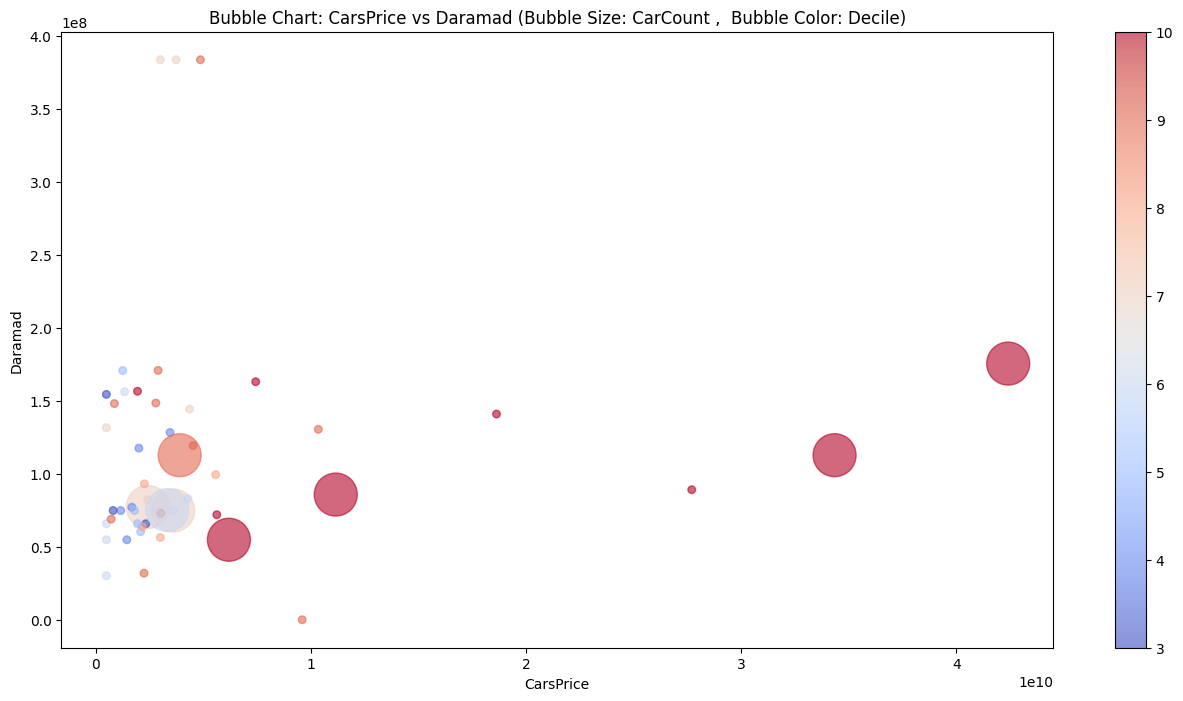

In [24]:
df_sample.plot(
    kind = 'scatter', x='CarsPrice',y='Daramad',figsize=(16,8),s=df_sample['CarsCount'] ** 5 * 30,
    alpha = 0.6,c=df_sample['Decile'],cmap="coolwarm" , title='Bubble Chart: CarsPrice vs Daramad (Bubble Size: CarCount ,  Bubble Color: Decile)')


# Bookeh:

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
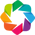

In [25]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
import holoviews as hv
hv.extension('bokeh')
output_notebook()


df_t = df[['Age' , 'CardBeCardPerMonth_1402' , 'SatnaPerMonth_1402' , 'PayaPerMonth_1402']].groupby('Age').mean()

# Now let's create the figure and set the labels
plot = figure(x_axis_label=("Age"), y_axis_label=("Rial"),
              title="Different transactions mean values based on age",
              width=800, height=400)




plot.line(x=df_t.index, y=df_t['CardBeCardPerMonth_1402'], color="green", line_width=4)
plot.line(x=df_t.index, y=df_t['SatnaPerMonth_1402'], color="red", line_width=4)
plot.line(x=df_t.index, y=df_t['PayaPerMonth_1402'], color="yellow", line_width=4)
plot.legend.location = "top_left"

show(plot)

In [27]:
# Using logarithms to reduce the impact of very large values and data dispersion.

df['MandehAkhar_1399log']=np.log(df["MandehAkhar_1399"]+1)
df['MandehAval_1399log']=np.log(df["MandehAval_1399"]+1)
df['MandehAval_1400log']=np.log(df["MandehAval_1400"]+1)
df['MandehAkhar_1400log']=np.log(df["MandehAkhar_1400"]+1)
df['CardPerMonth_1398log']=np.log(df["CardPerMonth_1398"]+1)
df['PayaPerMonth_1402log']=np.log(df["PayaPerMonth_1402"]+1)
df['Bourse_NetPortfoValuelog']=np.log(df["Bourse_NetPortfoValue"]+1)
df['PayaPerMonth_1401log']=np.log(df["PayaPerMonth_1401"]+1)
df['CardPerMonth_1398log']=np.log(df["CardPerMonth_1398"]+1)
df['CardPerMonth_1399log']=np.log(df["CardPerMonth_1399"]+1)
df['CardPerMonth_1400log']=np.log(df["CardPerMonth_1400"]+1)
df['CardPerMonth_1401log']=np.log(df["CardPerMonth_1401"]+1)
df['CardPerMonth_1402log']=np.log(df["CardPerMonth_1402"]+1)
df['CardBeCardPerMonth_1401log']=np.log(df["CardBeCardPerMonth_1401"]+1)
df['CardBeCardPerMonth_1402log']=np.log(df["CardBeCardPerMonth_1402"]+1)
df['SatnaPerMonth_1401log']=np.log(df["SatnaPerMonth_1401"]+1)
df['SatnaPerMonth_1402log']=np.log(df["SatnaPerMonth_1402"]+1)


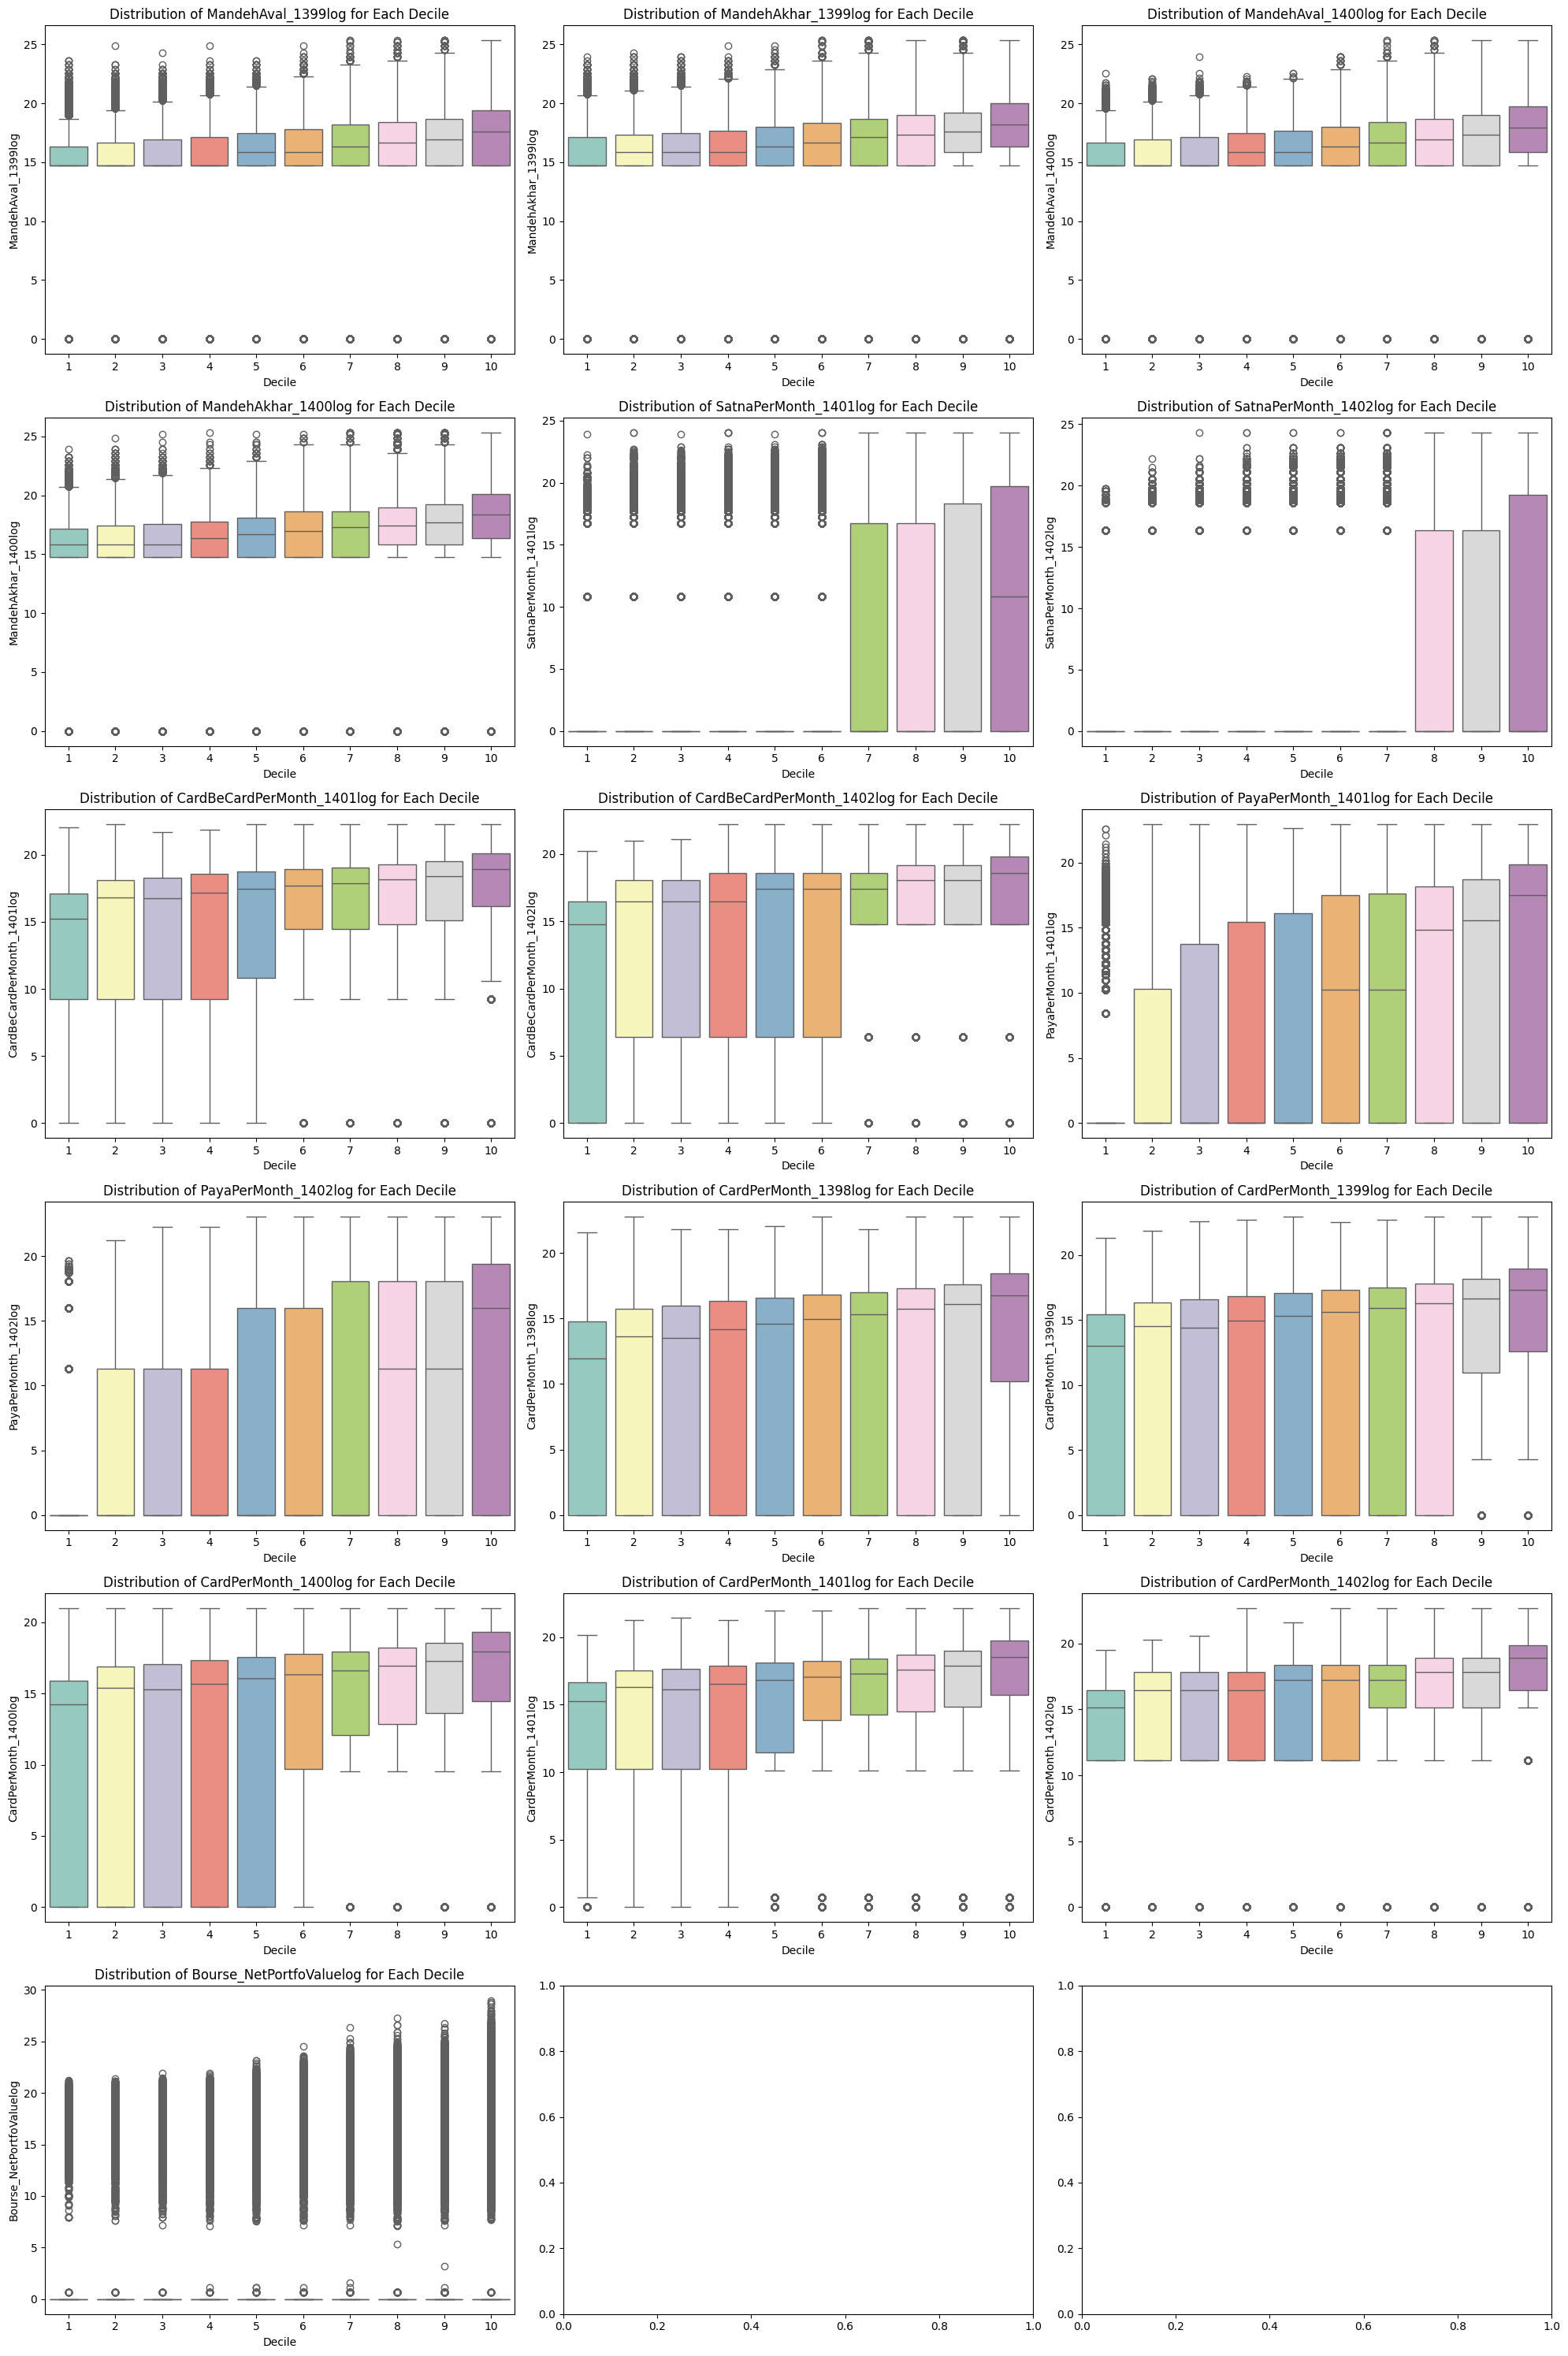

In [28]:
fig, axes = plt.subplots(6, 3, figsize=(20, 30), sharey=False)

sns.boxplot(data=df, x='Decile', y='MandehAval_1399log', palette='Set3', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of MandehAval_1399log for Each Decile')
axes[0, 0].set_ylabel('MandehAval_1399log')
sns.boxplot(x='Decile', y='MandehAkhar_1399log', data=df, palette='Set3', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of MandehAkhar_1399log for Each Decile')
axes[0,1].set_ylabel('MandehAkhar_1399log')
sns.boxplot(data=df, x='Decile', y='MandehAval_1400log', palette='Set3', ax=axes[0, 2])
axes[0, 2].set_title('Distribution of MandehAval_1400log for Each Decile')
axes[0, 2].set_ylabel('MandehAval_1400log')
sns.boxplot(data=df, x='Decile', y='MandehAkhar_1400log', palette='Set3', ax=axes[1,0])
axes[1, 0].set_title('Distribution of MandehAkhar_1400log for Each Decile')
axes[1, 0].set_ylabel('MandehAkhar_1400log')


sns.boxplot(data=df, x='Decile', y='SatnaPerMonth_1401log', palette='Set3', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of SatnaPerMonth_1401log for Each Decile')
axes[1, 1].set_ylabel('SatnaPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='SatnaPerMonth_1402log', palette='Set3', ax=axes[1, 2])
axes[1, 2].set_title('Distribution of SatnaPerMonth_1402log for Each Decile')
axes[1, 2].set_ylabel('SatnaPerMonth_1402log')



sns.boxplot(data=df, x='Decile', y='CardBeCardPerMonth_1401log', palette='Set3', ax=axes[2, 0])
axes[2, 0].set_title('Distribution of CardBeCardPerMonth_1401log for Each Decile')
axes[2, 0].set_ylabel('CardBeCardPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='CardBeCardPerMonth_1402log', palette='Set3', ax=axes[2, 1])
axes[2, 1].set_title('Distribution of CardBeCardPerMonth_1402log for Each Decile')
axes[2, 1].set_ylabel('CardBeCardPerMonth_1402log')

sns.boxplot(data=df, x='Decile', y='PayaPerMonth_1401log', palette='Set3', ax=axes[2, 2])
axes[2, 2].set_title('Distribution of PayaPerMonth_1401log for Each Decile')
axes[2, 2].set_ylabel('PayaPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='PayaPerMonth_1402log', palette='Set3', ax=axes[3, 0])
axes[3, 0].set_title('Distribution of PayaPerMonth_1402log for Each Decile')
axes[3, 0].set_ylabel('PayaPerMonth_1402log')


sns.boxplot(data=df, x='Decile', y='CardPerMonth_1398log', palette='Set3', ax=axes[3, 1])
axes[3, 1].set_title('Distribution of CardPerMonth_1398log for Each Decile')
axes[3, 1].set_ylabel('CardPerMonth_1398log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1399log', palette='Set3', ax=axes[3, 2])
axes[3, 2].set_title('Distribution of CardPerMonth_1399log for Each Decile')
axes[3, 2].set_ylabel('CardPerMonth_1399log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1400log', palette='Set3', ax=axes[4, 0])
axes[4, 0].set_title('Distribution of CardPerMonth_1400log for Each Decile')
axes[4, 0].set_ylabel('CardPerMonth_1400log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1401log', palette='Set3', ax=axes[4,1])
axes[4, 1].set_title('Distribution of CardPerMonth_1401log for Each Decile')
axes[4, 1].set_ylabel('CardPerMonth_1401log')
sns.boxplot(data=df, x='Decile', y='CardPerMonth_1402log', palette='Set3', ax=axes[4,2])
axes[4, 2].set_title('Distribution of CardPerMonth_1402log for Each Decile')
axes[4, 2].set_ylabel('CardPerMonth_1402log')



sns.boxplot(data=df, x='Decile', y='Bourse_NetPortfoValuelog', palette='Set3', ax=axes[5, 0])
axes[5, 0].set_title('Distribution of Bourse_NetPortfoValuelog for Each Decile')
axes[5, 0].set_ylabel('Bourse_NetPortfoValuelog')


# for ax in axes[0:, :]:
#     ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')



fig.tight_layout()
plt.show()


-------------------------